# Análise Spotify com Polars
**Parte 2.2 **
Dataset: `spotify_music.parquet` (gerado na Parte 2.1)
Schema: 114.000 × 23 colunas

In [15]:
import os
import time
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## 1. Leitura Lazy do Parquet

In [16]:
CAMINHO = "spotify_music.parquet"
if not os.path.exists(CAMINHO):
    CAMINHO = os.path.join(os.getcwd(), "..", "spotify_music.parquet")
if not os.path.exists(CAMINHO):
    raise FileNotFoundError("Rode a Parte 2.1 primeiro.")

inicial = pl.scan_parquet(CAMINHO)   # LazyFrame
df_raw = inicial.collect()

print(f"📦 Parquet bruto: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
print(f"Colunas: {df_raw.columns}")

📦 Parquet bruto: 114000 linhas x 23 colunas
Colunas: ['', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre', 'duration_min', 'main_artist']


## 2. Limpeza mínima para análise
A limpeza afeta apenas o DataFrame em memória — o Parquet bruto não é alterado.

In [17]:
numeric_cols = [
    "popularity", "duration_min", "danceability", "energy",
    "loudness", "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo",
]

nulos_antes = df_raw.select(
    [pl.col(c).is_null().sum().alias(c) for c in numeric_cols]
)
print("🧹 Nulos antes da limpeza:")
print(nulos_antes)

df = (
    df_raw
    .drop_nulls(subset=["energy", "loudness", "popularity", "track_id"])
    .unique(subset=["track_id"])
)

print(f"\n✅ Após limpeza: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"   Removidas: {df_raw.shape[0] - df.shape[0]} linhas")

🧹 Nulos antes da limpeza:
shape: (1, 11)
┌────────────┬──────────────┬──────────────┬────────┬───┬─────────────┬──────────┬─────────┬───────┐
│ popularity ┆ duration_min ┆ danceability ┆ energy ┆ … ┆ instrumenta ┆ liveness ┆ valence ┆ tempo │
│ ---        ┆ ---          ┆ ---          ┆ ---    ┆   ┆ lness       ┆ ---      ┆ ---     ┆ ---   │
│ u32        ┆ u32          ┆ u32          ┆ u32    ┆   ┆ ---         ┆ u32      ┆ u32     ┆ u32   │
│            ┆              ┆              ┆        ┆   ┆ u32         ┆          ┆         ┆       │
╞════════════╪══════════════╪══════════════╪════════╪═══╪═════════════╪══════════╪═════════╪═══════╡
│ 0          ┆ 0            ┆ 0            ┆ 0      ┆ … ┆ 0           ┆ 0        ┆ 0       ┆ 0     │
└────────────┴──────────────┴──────────────┴────────┴───┴─────────────┴──────────┴─────────┴───────┘

✅ Após limpeza: 89741 linhas x 23 colunas
   Removidas: 24259 linhas


## 3. Filtros e seleção no LazyFrame

In [18]:
q_populares   = inicial.filter(pl.col("popularity") > 50)
q_energeticas = inicial.filter((pl.col("energy") > 0.8) & (pl.col("popularity") > 50))
q_generos     = inicial.filter(
    pl.col("track_genre").is_in(["pop", "rock", "hip-hop", "acoustic"])
)
q_simples     = inicial.select(
    ["track_name", "main_artist", "energy", "loudness", "popularity"]
)
q_sem_ids     = inicial.select(pl.exclude(["track_id", "album_name"]))

print("📌 Filtrando dados:")
print(f"   popularity > 50          : {q_populares.collect().shape[0]}")
print(f"   energéticas (>0.8)       : {q_energeticas.collect().shape[0]}")
print(f"   gêneros selecionados     : {q_generos.collect().shape[0]}")

📌 Filtrando dados:
   popularity > 50          : 27770
   energéticas (>0.8)       : 8070
   gêneros selecionados     : 4000


## 4. Slicing

In [19]:
print("🔪 Slicing:")
print("head(5):")
display(inicial.head(5).collect())

print("slice(100, 10):")
display(inicial.slice(100, 10).collect())

q_recorte = (
    inicial
    .with_row_index("id_linha")
    .filter(pl.col("id_linha").is_in([0, 10, 50, 100]))
    .select(["id_linha", "track_name", "main_artist", "popularity"])
)
print("Recorte por índices [0, 10, 50, 100]:")
display(q_recorte.collect())

🔪 Slicing:
head(5):


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_min,main_artist
i64,str,str,str,str,i32,i64,bool,f64,f64,i32,f64,i32,f64,f64,f64,f64,f64,f64,i32,str,f64,str
0,"""5SuOikwiRyPMVoIQDJUgSV""","""Gen Hoshino""","""Comedy""","""Comedy""",73,230666,false,0.676,0.461,1,-6.746,0,0.143,0.0322,0.000001,0.358,0.715,87.917,4,"""acoustic""",3.84,"""Gen Hoshino"""
1,"""4qPNDBW1i3p13qLCt0Ki3A""","""Ben Woodward""","""Ghost (Acoustic)""","""Ghost - Acoustic""",55,149610,false,0.42,0.166,1,-17.235,1,0.0763,0.924,0.000006,0.101,0.267,77.489,4,"""acoustic""",2.49,"""Ben Woodward"""
2,"""1iJBSr7s7jYXzM8EGcbK5b""","""Ingrid Michaelson;ZAYN""","""To Begin Again""","""To Begin Again""",57,210826,false,0.438,0.359,0,-9.734,1,0.0557,0.21,0.0,0.117,0.12,76.332,4,"""acoustic""",3.51,"""Ingrid Michaelson"""
3,"""6lfxq3CG4xtTiEg7opyCyx""","""Kina Grannis""","""Crazy Rich Asians (Original Mo…","""Can't Help Falling In Love""",71,201933,false,0.266,0.0596,0,-18.515,1,0.0363,0.905,0.0000707,0.132,0.143,181.74,3,"""acoustic""",3.37,"""Kina Grannis"""
4,"""5vjLSffimiIP26QG5WcN2K""","""Chord Overstreet""","""Hold On""","""Hold On""",82,198853,false,0.618,0.443,2,-9.681,1,0.0526,0.469,0.0,0.0829,0.167,119.949,4,"""acoustic""",3.31,"""Chord Overstreet"""


slice(100, 10):


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_min,main_artist
i64,str,str,str,str,i32,i64,bool,f64,f64,i32,f64,i32,f64,f64,f64,f64,f64,f64,i32,str,f64,str
100,"""0U32q8CZRRo7xCzyiaZw5f""","""Motohiro Hata""","""言ノ葉""","""Rain""",58,293040,false,0.626,0.655,9,-6.69,1,0.0263,0.503,0.0,0.13,0.542,92.003,4,"""acoustic""",4.88,"""Motohiro Hata"""
101,"""4kQXMVjoZ9yMibLZq5Aqi5""","""Callum J Wright""","""Somebody Else (Acoustic)""","""Somebody Else - Acoustic""",50,138495,false,0.794,0.38,10,-8.769,0,0.0477,0.762,0.0,0.262,0.617,114.99,4,"""acoustic""",2.31,"""Callum J Wright"""
102,"""3us8sod4dLbM9FiMiPiEY8""","""Andrew Belle""","""Black Bear (Hushed)""","""Pieces (Hushed)""",59,198626,false,0.52,0.279,5,-10.739,0,0.0547,0.894,0.000105,0.103,0.0951,69.642,4,"""acoustic""",3.31,"""Andrew Belle"""
103,"""1PR5pyPiOEEQ02oJYq402x""","""Boyce Avenue;Fifth Harmony""","""Cover Sessions, Vol. 3""","""Mirrors""",57,292566,false,0.545,0.658,1,-7.174,1,0.0474,0.496,0.0,0.105,0.683,76.971,4,"""acoustic""",4.88,"""Boyce Avenue"""
104,"""068qo0w1Ki0cjnFYOUhAm2""","""Boyce Avenue""","""Stand by Me""","""Stand by Me""",60,199019,false,0.728,0.266,8,-7.322,1,0.0293,0.872,0.0000103,0.114,0.307,115.189,4,"""acoustic""",3.32,"""Boyce Avenue"""
105,"""2RFt6ZWQbr9mPhsft9u9eX""","""Gabrielle Aplin;JP Cooper""","""Dear Happy""","""Losing Me""",61,181760,false,0.66,0.407,7,-8.381,1,0.0571,0.236,0.0,0.109,0.257,133.86,4,"""acoustic""",3.03,"""Gabrielle Aplin"""
106,"""59pUIlXjQupbiYwt40uUTi""","""Mone Kamishiraishi""","""chouchou""","""なんでもないや - movie ver.""",49,349920,false,0.357,0.161,8,-10.667,1,0.0388,0.971,0.000014,0.358,0.325,83.449,4,"""acoustic""",5.83,"""Mone Kamishiraishi"""
107,"""0VhZ5JYfqPojSYeGWnk4dL""","""John Adams""","""You’re Beautiful (Acoustic)""","""You’re Beautiful - Acoustic""",55,204973,false,0.479,0.154,2,-11.282,1,0.0352,0.915,0.0,0.0974,0.36,147.207,4,"""acoustic""",3.42,"""John Adams"""
108,"""0ltIx8PLjtWoS9zn9PqsZW""","""Kitri""","""Hikare Inochi""","""Hikare Inochi""",51,322146,false,0.592,0.769,2,-5.268,1,0.0311,0.319,0.000005,0.137,0.385,102.033,4,"""acoustic""",5.37,"""Kitri"""


Recorte por índices [0, 10, 50, 100]:


id_linha,track_name,main_artist,popularity
u32,str,str,i32
0,"""Comedy""","""Gen Hoshino""",73
10,"""Give Me Your Forever""","""Zack Tabudlo""",74
50,"""Trampoline - Acoustic""","""Highland Peak""",46
100,"""Rain""","""Motohiro Hata""",58


## 5. Condicional `pl.when / then / otherwise`

In [20]:
q_categoria = inicial.with_columns(
    pl.when(pl.col("popularity") >= 70).then(pl.lit("Hit"))
      .when(pl.col("popularity") >= 40).then(pl.lit("Média"))
      .otherwise(pl.lit("Baixa"))
      .alias("CATEGORIA_POPULARIDADE")
)

q_analise_categoria = (
    q_categoria
    .group_by("CATEGORIA_POPULARIDADE")
    .agg([
        pl.len().alias("total_musicas"),
        pl.col("energy").mean().alias("energy_media"),
        pl.col("loudness").mean().alias("loudness_media"),
        pl.col("tempo").mean().alias("tempo_medio"),
        pl.col("duration_min").mean().alias("duracao_media"),
    ])
    .sort("energy_media", descending=True)
)

print("📊 Análise por categoria de popularidade:")
display(q_analise_categoria.collect())

📊 Análise por categoria de popularidade:


CATEGORIA_POPULARIDADE,total_musicas,energy_media,loudness_media,tempo_medio,duracao_media
str,u32,f64,f64,f64,f64
"""Hit""",5472,0.671062,-6.663338,120.133624,3.640833
"""Baixa""",65413,0.64875,-8.44726,122.02531,3.810053
"""Média""",43115,0.626439,-8.175788,122.58937,3.806192


## 6. Group_by + Agg

In [21]:
q_stats_genero = (
    inicial
    .group_by("track_genre")
    .agg([
        pl.len().alias("total_musicas"),
        pl.col("popularity").mean().alias("popularidade_media"),
        pl.col("energy").mean().alias("energy_media"),
        pl.col("loudness").mean().alias("loudness_media"),
        pl.col("tempo").mean().alias("tempo_medio"),
        pl.col("duration_min").mean().alias("duracao_media"),
    ])
    .sort("popularidade_media", descending=True)
)

print("🎵 Top gêneros por popularidade média:")
display(q_stats_genero.head(10).collect())

🎵 Top gêneros por popularidade média:


track_genre,total_musicas,popularidade_media,energy_media,loudness_media,tempo_medio,duracao_media
str,u32,f64,f64,f64,f64,f64
"""pop-film""",1000,59.283,0.6045619,-7.871622,117.257478,4.66079
"""k-pop""",1000,56.896,0.675654,-6.470775,119.243969,4.18791
"""chill""",1000,53.651,0.426723,-10.460978,115.479376,2.81675
"""sad""",1000,52.379,0.4624701,-10.275018,119.06495,2.56319
"""grunge""",1000,49.594,0.80329,-5.66096,129.349208,3.9263
"""indian""",1000,49.539,0.567121,-8.850844,116.142954,4.09104
"""anime""",1000,48.772,0.6741083,-7.932289,123.529616,3.50333
"""emo""",1000,48.128,0.669967,-6.718621,126.992643,3.16157
"""sertanejo""",1000,47.866,0.710391,-5.485445,127.052197,3.40979


In [22]:
q_stats_artist = (
    inicial
    .group_by("main_artist")
    .agg([
        pl.len().alias("total_musicas"),
        pl.col("popularity").mean().alias("popularidade_media"),
        pl.col("popularity").max().alias("maior_popularidade"),
    ])
    .filter(pl.col("total_musicas") >= 3)
    .sort("popularidade_media", descending=True)
    .head(15)
)

print("🎤 Top artistas (com ≥3 músicas):")
display(q_stats_artist.collect())

🎤 Top artistas (com ≥3 músicas):


main_artist,total_musicas,popularidade_media,maior_popularidade
str,u32,f64,i32
"""Manuel Turizo""",4,98.0,98
"""Harry Styles""",3,92.0,95
"""Luar La L""",4,90.5,91
"""Olivia Rodrigo""",5,87.4,88
"""The Kid LAROI""",6,85.166667,89
…,…,…,…
"""Nicki Minaj""",4,83.5,92
"""Lil Nas X""",11,83.454545,90
"""Morgan Wallen""",3,83.333333,86


## 7. Benchmark: `StringCache`

In [23]:
print("=== BENCHMARK: group_by SEM vs COM StringCache ===")

t0 = time.time()
_ = (
    inicial.group_by("track_genre")
    .agg(pl.col("popularity").mean().alias("media"))
    .collect()
)
t_sem = time.time() - t0
print(f"Tempo SEM Cache : {t_sem:.4f}s")

with pl.StringCache():
    t0 = time.time()
    df_cache = (
        inicial.group_by("track_genre")
        .agg(pl.col("popularity").mean().alias("media"))
        .collect()
    )
    t_com = time.time() - t0

print(f"Tempo COM Cache : {t_com:.4f}s")
print(f"Memória coluna 'track_genre': {df_cache['track_genre'].estimated_size()} bytes")

=== BENCHMARK: group_by SEM vs COM StringCache ===
Tempo SEM Cache : 0.0051s
Tempo COM Cache : 0.0032s
Memória coluna 'track_genre': 806 bytes


C:\Users\rafael.chousa\AppData\Local\Temp\ipykernel_14636\1601895688.py:12: DeprecationWarning: the string cache has been replaced by pl.Categories
  with pl.StringCache():


## 8. Estatísticas descritivas

In [24]:
print("=" * 60)
print("--- Estatísticas Descritivas ---")
print("=" * 60)

for col in ["popularity", "energy", "loudness", "tempo"]:
    metricas = df.select([
        pl.col(col).mean().alias("Média"),
        pl.col(col).median().alias("Mediana"),
        pl.col(col).mode().first().alias("Moda"),
        pl.col(col).var().alias("Variância"),
        pl.col(col).std().alias("Desvio_Padrão"),
        (pl.col(col).max() - pl.col(col).min()).alias("Amplitude"),
    ])
    print(f"\n▶ {col}")
    display(metricas)

--- Estatísticas Descritivas ---

▶ popularity


Média,Mediana,Moda,Variância,Desvio_Padrão,Amplitude
f64,f64,i32,f64,f64,i32
33.198438,33.0,0,423.570317,20.580824,100



▶ energy


Média,Mediana,Moda,Variância,Desvio_Padrão,Amplitude
f64,f64,f64,f64,f64,f64
0.634458,0.676,0.961,0.065846,0.256605,1.0



▶ loudness


Média,Mediana,Moda,Variância,Desvio_Padrão,Amplitude
f64,f64,f64,f64,f64,f64
-8.499004,-7.185,-5.956,27.263953,5.22149,54.063



▶ tempo


Média,Mediana,Moda,Variância,Desvio_Padrão,Amplitude
f64,f64,f64,f64,f64,f64
122.058316,122.013,0.0,907.065737,30.117532,243.372


In [ ]:
cols_stats = ["popularity", "energy", "loudness"]

metricas2 = df.select(
    [pl.col(c).quantile(0.25).alias(f"{c}_Q1") for c in cols_stats]
    + [pl.col(c).quantile(0.50).alias(f"{c}_Q2") for c in cols_stats]
    + [pl.col(c).quantile(0.75).alias(f"{c}_Q3") for c in cols_stats]
    + [pl.col(c).skew().alias(f"{c}_assim")    for c in cols_stats]
    + [pl.col(c).kurtosis().alias(f"{c}_curt") for c in cols_stats]
)
display(metricas2)

assimetria = df.select(pl.col("popularity").skew()).item()
print(f"\nAssimetria de popularity ({assimetria:.2f}):")
if -0.5 <= assimetria <= 0.5:
    print("  → Distribuição Simétrica")
elif assimetria > 0.5:
    print("  → Assimétrica Positiva (poucas músicas muito populares)")
else:
    print("  → Assimétrica Negativa")

## 9. Outliers por IQR

In [25]:
def detectar_outliers(df, coluna):
    Q1 = df.select(pl.col(coluna).quantile(0.25)).item()
    Q3 = df.select(pl.col(coluna).quantile(0.75)).item()
    IQR = Q3 - Q1
    LI, LS = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    out = df.filter((pl.col(coluna) < LI) | (pl.col(coluna) > LS))
    print(
        f"🔎 {coluna}: Q1={Q1:.2f}  Q3={Q3:.2f}  IQR={IQR:.2f}  "
        f"LI={LI:.2f}  LS={LS:.2f}  → {out.shape[0]} outliers "
        f"({100 * out.shape[0] / df.shape[0]:.2f}%)"
    )
    return LI, LS

for c in ["popularity", "energy", "loudness", "tempo"]:
    detectar_outliers(df, c)

🔎 popularity: Q1=19.00  Q3=49.00  IQR=30.00  LI=-26.00  LS=94.00  → 11 outliers (0.01%)
🔎 energy: Q1=0.46  Q3=0.85  IQR=0.40  LI=-0.14  LS=1.45  → 0 outliers (0.00%)
🔎 loudness: Q1=-10.32  Q3=-5.11  IQR=5.21  LI=-18.14  LS=2.71  → 5026 outliers (5.60%)
🔎 tempo: Q1=99.26  Q3=140.08  IQR=40.81  LI=38.04  LS=201.30  → 514 outliers (0.57%)


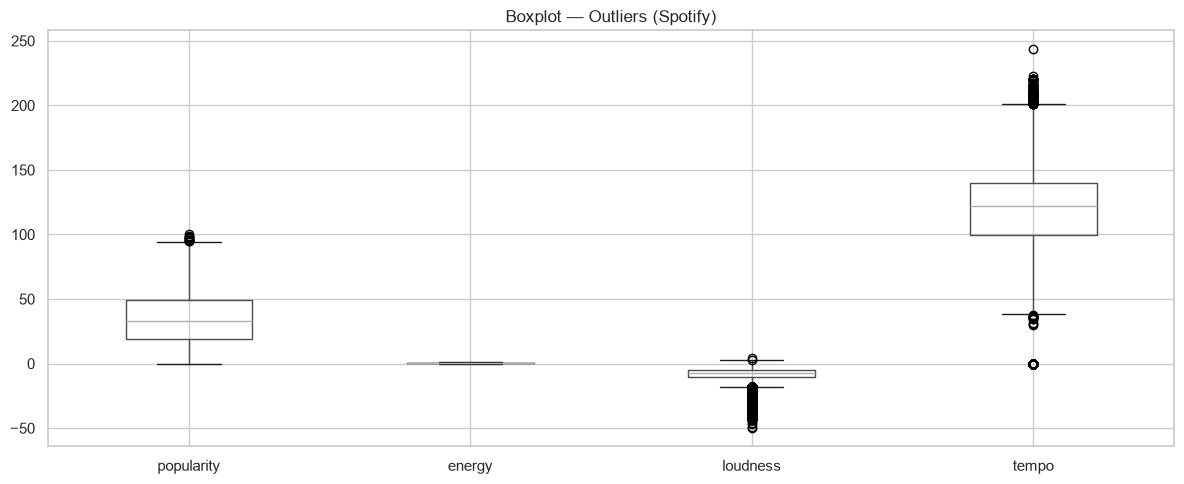

In [33]:
plt.figure(figsize=(12, 5))
df.select(["popularity", "energy", "loudness", "tempo"]).to_pandas().boxplot()
plt.title("Boxplot — Outliers (Spotify)")
plt.tight_layout()
plt.show()

🔎 popularity: Q1=19.00  Q3=49.00  IQR=30.00  LI=-26.00  LS=94.00  → 11 outliers (0.01%)


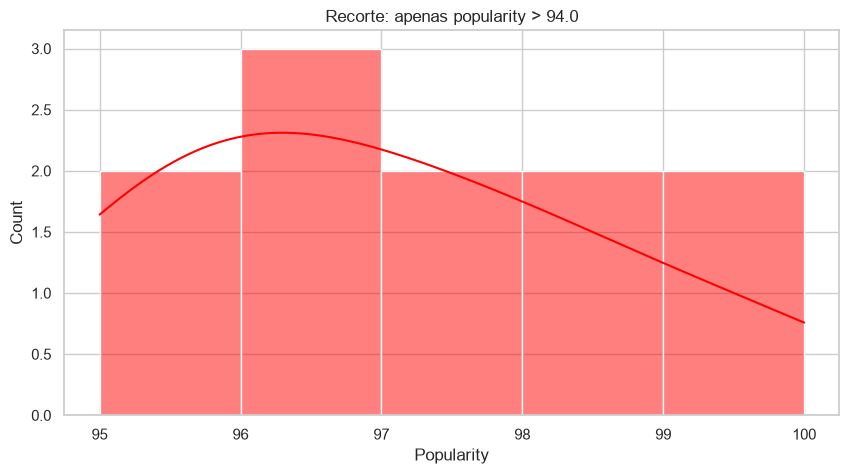

In [34]:
LI, LS = detectar_outliers(df, "popularity")
superiores = df.filter(pl.col("popularity") > LS).select("popularity").to_series()

plt.figure(figsize=(10, 5))
sns.histplot(superiores, kde=True, color="red")
plt.title(f"Recorte: apenas popularity > {LS:.1f}")
plt.xlabel("Popularity")
plt.show()

## 10. Correlação de Pearson (nível da música)

📈 Matriz de Correlação (Pearson) — nível da música:
shape: (11, 11)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ popularit ┆ duration_ ┆ danceabil ┆ energy    ┆ … ┆ instrumen ┆ liveness  ┆ valence   ┆ tempo    │
│ y         ┆ min       ┆ ity       ┆ ---       ┆   ┆ talness   ┆ ---       ┆ ---       ┆ ---      │
│ ---       ┆ ---       ┆ ---       ┆ f64       ┆   ┆ ---       ┆ f64       ┆ f64       ┆ f64      │
│ f64       ┆ f64       ┆ f64       ┆           ┆   ┆ f64       ┆           ┆           ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 1.0       ┆ -0.023114 ┆ 0.064281  ┆ 0.013728  ┆ … ┆ -0.127465 ┆ -0.013844 ┆ -0.011526 ┆ 0.00727  │
│ -0.023114 ┆ 1.0       ┆ -0.064133 ┆ 0.063257  ┆ … ┆ 0.117382  ┆ 0.008126  ┆ -0.147039 ┆ 0.02599  │
│ 0.064281  ┆ -0.064133 ┆ 1.0       ┆ 0.143914  ┆ … ┆ -0.194747 ┆ -0.132234 ┆ 0.492571  ┆ -0.02133 │
│           ┆          

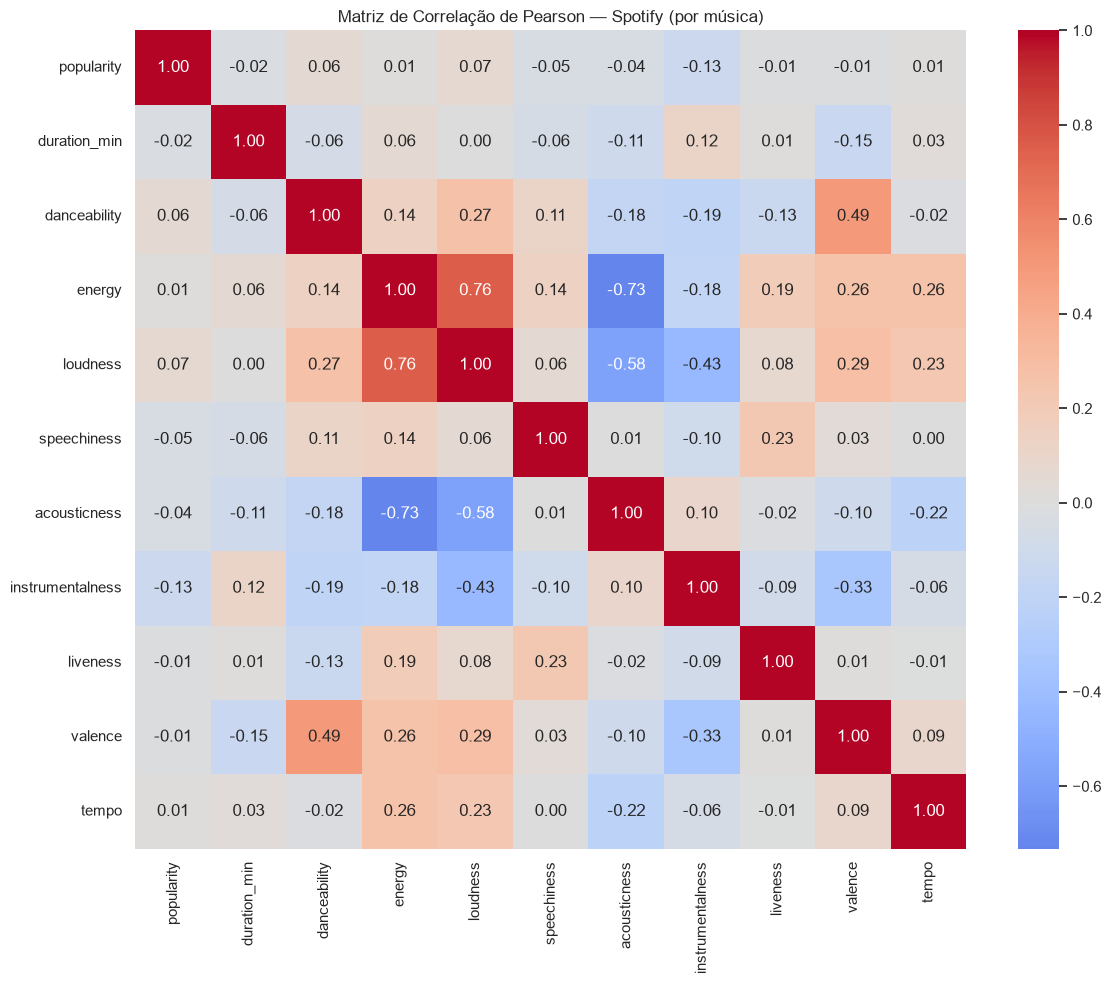

In [32]:
corr = df.select(numeric_cols).corr()
print("📈 Matriz de Correlação (Pearson) — nível da música:")
print(corr)

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr.to_numpy(), annot=True, fmt=".2f",
    cmap="coolwarm", center=0,
    xticklabels=numeric_cols, yticklabels=numeric_cols,
)
plt.title("Matriz de Correlação de Pearson — Spotify (por música)")
plt.tight_layout()
plt.show()

🔗 Correlação por música: energy × loudness → r = 0.7588  |  r² = 0.5757
→ Correlação FORTE e POSITIVA


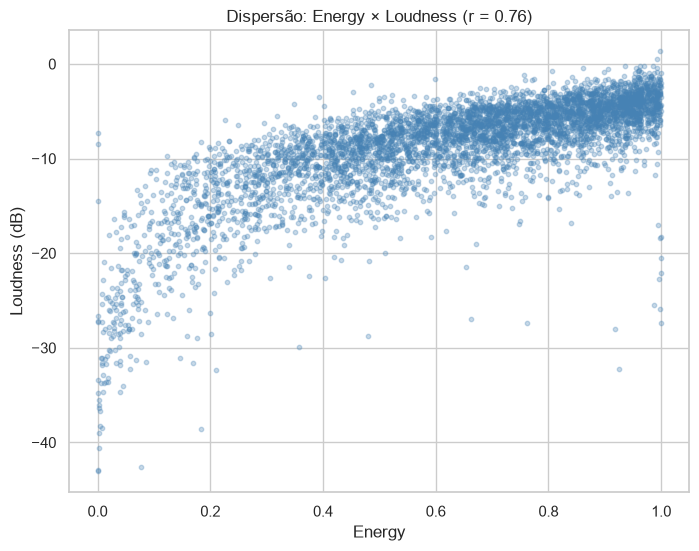

In [31]:
r = df.select(pl.corr("energy", "loudness", method="pearson")).item()
print(f"🔗 Correlação por música: energy × loudness → r = {r:.4f}  |  r² = {r**2:.4f}")

if abs(r) >= 0.7:    cls = "FORTE"
elif abs(r) >= 0.3:  cls = "MODERADA"
else:                cls = "FRACA"
direcao = "POSITIVA" if r > 0 else "NEGATIVA"
print(f"→ Correlação {cls} e {direcao}")

amostra = df.sample(n=min(5000, df.shape[0]), seed=42).to_pandas()
plt.figure(figsize=(8, 6))
plt.scatter(amostra["energy"], amostra["loudness"], alpha=0.3, s=10, color="steelblue")
plt.xlabel("Energy")
plt.ylabel("Loudness (dB)")
plt.title(f"Dispersão: Energy × Loudness (r = {r:.2f})")
plt.show()

## 10.1 Correlação por granularidade agrupada (por gênero)

In [28]:
print("=" * 60)
print("--- Correlação por GRANULARIDADE AGRUPADA (por gênero) ---")
print("=" * 60)

df_genero = (
    inicial
    .group_by("track_genre")
    .agg([
        pl.len().alias("qtd_musicas"),
        pl.col("popularity").mean().alias("popularidade_media"),
        pl.col("energy").mean().alias("energy_media"),
        pl.col("loudness").mean().alias("loudness_media"),
        pl.col("tempo").mean().alias("tempo_medio"),
        pl.col("duration_min").mean().alias("duracao_media"),
    ])
    .collect()
)
print(f"Total de gêneros agrupados: {df_genero.shape[0]}")

r_gen = df_genero.select(
    pl.corr("qtd_musicas", "popularidade_media", method="pearson")
).item()
r_eng = df_genero.select(
    pl.corr("energy_media", "loudness_media", method="pearson")
).item()

print(f"\n🔗 Por gênero: qtd_musicas × popularidade_media  → r = {r_gen:.4f}  |  r² = {r_gen**2:.4f}")
print(f"🔗 Por gênero: energy_media × loudness_media     → r = {r_eng:.4f}  |  r² = {r_eng**2:.4f}")

if abs(r_gen) < 0.3:
    print("   → Correlação FRACA: tamanho do gênero não influencia a popularidade média.")
else:
    print("   → Correlação relevante.")

--- Correlação por GRANULARIDADE AGRUPADA (por gênero) ---
Total de gêneros agrupados: 114

🔗 Por gênero: qtd_musicas × popularidade_media  → r = nan  |  r² = nan
🔗 Por gênero: energy_media × loudness_media     → r = 0.8430  |  r² = 0.7107
   → Correlação relevante.


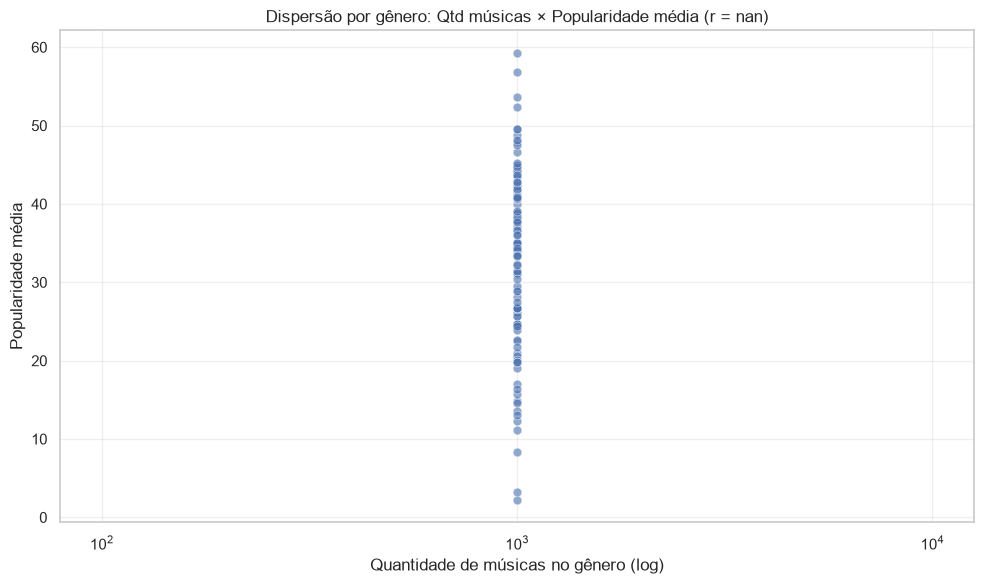

In [29]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_genero.to_pandas(),
    x="qtd_musicas", y="popularidade_media",
    alpha=0.6, s=40,
)
plt.xscale("log")
plt.title(f"Dispersão por gênero: Qtd músicas × Popularidade média (r = {r_gen:.2f})")
plt.xlabel("Quantidade de músicas no gênero (log)")
plt.ylabel("Popularidade média")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Regressão linear simples: `loudness ~ energy`

--- Regressão Linear Simples: loudness ~ energy ---
Equação: loudness = 15.44 * energy + -18.29
Coeficiente angular: 15.44 dB por unidade de energy
Intercepto         : -18.29 dB

Métricas:
  R²   : 0.5757
  MSE  : 11.57


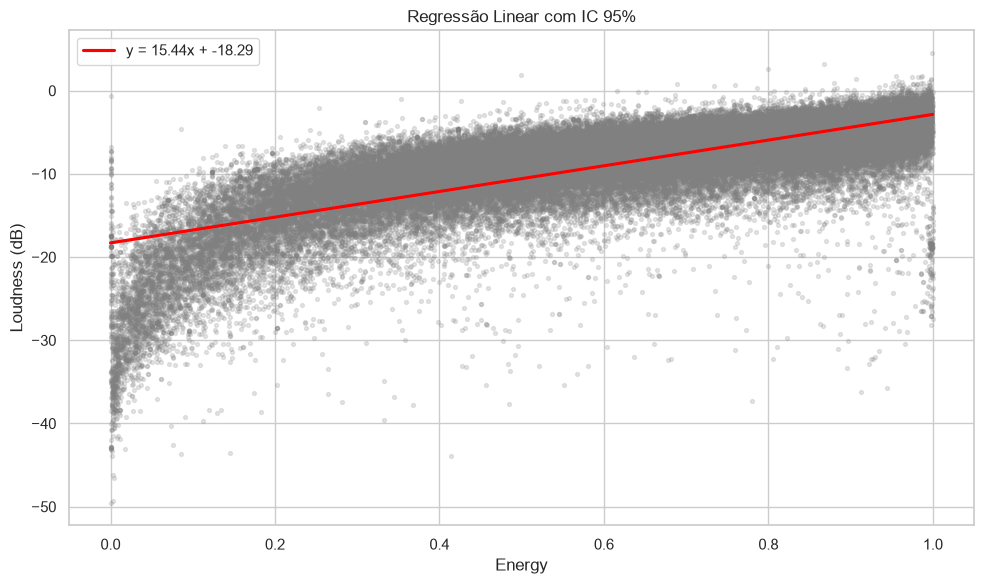

In [12]:
print("=" * 60)
print("--- Regressão Linear Simples: loudness ~ energy ---")
print("=" * 60)

X = df["energy"].to_numpy().reshape(-1, 1)
y = df["loudness"].to_numpy()

modelo = LinearRegression().fit(X, y)
a, b = modelo.coef_[0], modelo.intercept_

print(f"Equação: loudness = {a:.2f} * energy + {b:.2f}")
print(f"Coeficiente angular: {a:.2f} dB por unidade de energy")
print(f"Intercepto         : {b:.2f} dB")

y_pred = modelo.predict(X)
r2  = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print(f"\nMétricas:\n  R²   : {r2:.4f}\n  MSE  : {mse:.2f}")

plt.figure(figsize=(10, 6))
sns.regplot(
    x=X.flatten(), y=y, ci=95,
    line_kws={"color": "red", "label": f"y = {a:.2f}x + {b:.2f}"},
    scatter_kws={"alpha": 0.2, "s": 8, "color": "gray"},
)
plt.title("Regressão Linear com IC 95%")
plt.xlabel("Energy")
plt.ylabel("Loudness (dB)")
plt.legend()
plt.tight_layout()
plt.show()

## 11.1 Regressão múltipla por gênero

In [30]:
print("=" * 60)
print("--- Regressão por gênero: popularidade_media ~ features ---")
print("=" * 60)

feats = ["energy_media", "loudness_media", "tempo_medio", "duracao_media"]
Xg = df_genero.select(feats).to_numpy()
yg = df_genero["popularidade_media"].to_numpy()

mod_g = LinearRegression().fit(Xg, yg)
yg_pred = mod_g.predict(Xg)

print(f"  R²   : {r2_score(yg, yg_pred):.4f}")
print(f"  RMSE : {np.sqrt(mean_squared_error(yg, yg_pred)):.2f}")
print("  Coeficientes:")
for f, c in zip(feats, mod_g.coef_):
    print(f"    {f:20s}: {c:+.4f}")
print(f"  Intercepto: {mod_g.intercept_:.4f}")

--- Regressão por gênero: popularidade_media ~ features ---
  R²   : 0.0399
  RMSE : 11.02
  Coeficientes:
    energy_media        : -16.8620
    loudness_media      : +1.1076
    tempo_medio         : +0.0453
    duracao_media       : -0.3373
  Intercepto: 48.9440


## 12. Interpretação final

In [14]:
print("""
===================== INTERPRETAÇÃO =====================
1. energy × loudness (por música): correlação forte e positiva.
2. Regressão simples: R² alto — energy explica bem loudness.
3. popularity: assimétrica positiva (poucos hits).
4. Por gênero: correlação fraca entre qtd_musicas e
   popularidade_media — o tamanho do gênero não define
   a popularidade das músicas.
5. Regressão múltipla por gênero (extra): R² baixo é normal,
   popularidade depende de fatores externos.
==========================================================
""")


===================== INTERPRETAÇÃO =====================
1. energy × loudness (por música): correlação forte e positiva.
2. Regressão simples: R² alto — energy explica bem loudness.
3. popularity: assimétrica positiva (poucos hits).
4. Por gênero: correlação fraca entre qtd_musicas e
   popularidade_media — o tamanho do gênero não define
   a popularidade das músicas.
5. Regressão múltipla por gênero (extra): R² baixo é normal,
   popularidade depende de fatores externos.

